# Fig 1 choice CD analysis:

In [2]:

import sys
sys.path.append("C:\scripts\Imaging analysis")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
# import decon
from scipy.stats import chisquare
import pandas as pd
from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity

import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from activitymode import Mode

from ephysSession import Session
import behavior
cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 


In [16]:
naive_paths = [
                # r'J:\ephys_data\CW48\python\2024_10_29',
                # r'J:\ephys_data\CW48\python\2024_10_30',
                r'J:\ephys_data\CW48\python\2024_10_31',
                r'J:\ephys_data\CW48\python\2024_11_01',
                r'J:\ephys_data\CW48\python\2024_11_02',
                r'J:\ephys_data\CW48\python\2024_11_03',
                r'J:\ephys_data\CW48\python\2024_11_04',
                r'J:\ephys_data\CW48\python\2024_11_05',
                r'J:\ephys_data\CW48\python\2024_11_06',
                ]

trained_paths = [
            [ r'K:\data\CW69\python\2025_12_19',
              ],
            [r'L:\data\CW68\python\2025_12_10',
              r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            # [r'L:\data\CW70\python\2025_11_04',

            #  ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [r'H:\ephys_data\CW47\python\2024_10_17',
              r'H:\ephys_data\CW47\python\2024_10_22',
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
             
              ],
            [r'M:\data\CW87\python\2026_02_20',
              r'M:\data\CW87\python\2026_02_21',
              ],
            [r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_14',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],

              [
              r'P:\data\CW92\python\2026_06_17',
              r'P:\data\CW92\python\2026_06_18',
              r'P:\data\CW92\python\2026_06_19',
              r'P:\data\CW92\python\2026_06_21',
              r'P:\data\CW92\python\2026_06_23',
              r'P:\data\CW92\python\2026_06_24',
              r'P:\data\CW92\python\2026_06_25',
              r'P:\data\CW92\python\2026_06_26',
              r'P:\data\CW92\python\2026_06_27',
              r'P:\data\CW92\python\2026_06_28',
              r'P:\data\CW92\python\2026_06_29',
              r'P:\data\CW92\python\2026_06_30',
              r'P:\data\CW92\python\2026_07_01',

             ]

             
            ]



## Naive choice CD:

16 trials removed for stability reasons
only ppyr neurons: 299 --> 147
in house train test sorting
time taken: 22.130892992019653


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


calculation time: 0.2141110897064209


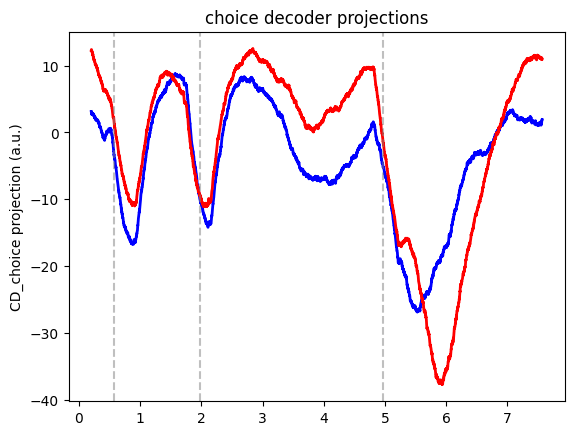

11 trials removed for stability reasons
only ppyr neurons: 225 --> 81
in house train test sorting
time taken: 10.591238021850586
calculation time: 0.06455039978027344


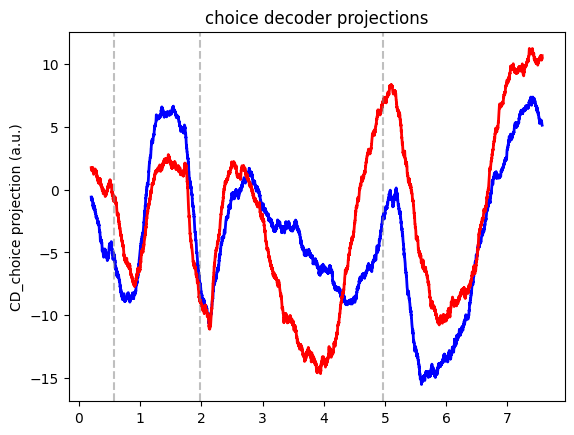

28 trials removed for stability reasons
only ppyr neurons: 270 --> 147
in house train test sorting
time taken: 22.283580780029297
calculation time: 0.11633133888244629


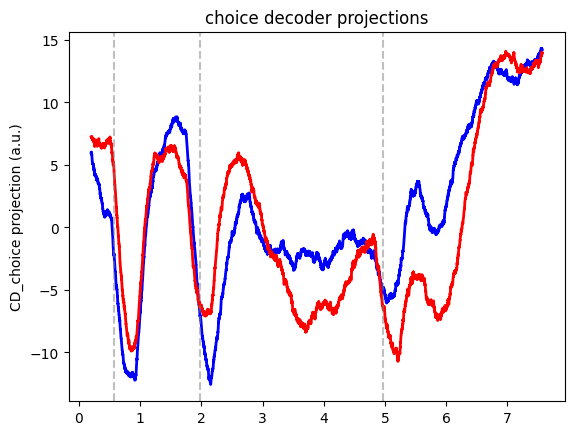

84 trials removed for stability reasons
only ppyr neurons: 268 --> 132
in house train test sorting
time taken: 14.312783241271973
calculation time: 0.11143255233764648


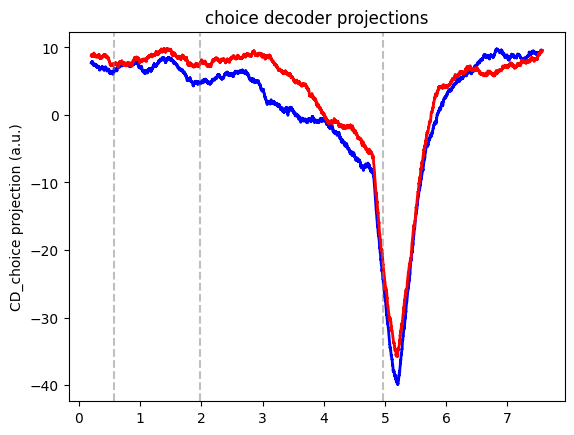

26 trials removed for stability reasons
only ppyr neurons: 241 --> 103
in house train test sorting
time taken: 12.004324674606323
calculation time: 0.08807706832885742


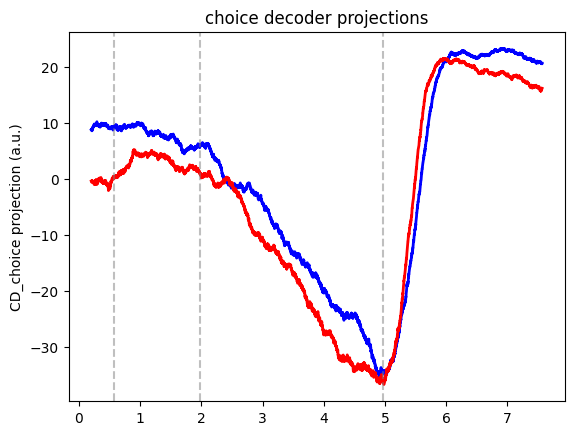

47 trials removed for stability reasons
only ppyr neurons: 295 --> 84
in house train test sorting
time taken: 8.367578029632568
calculation time: 0.06452035903930664


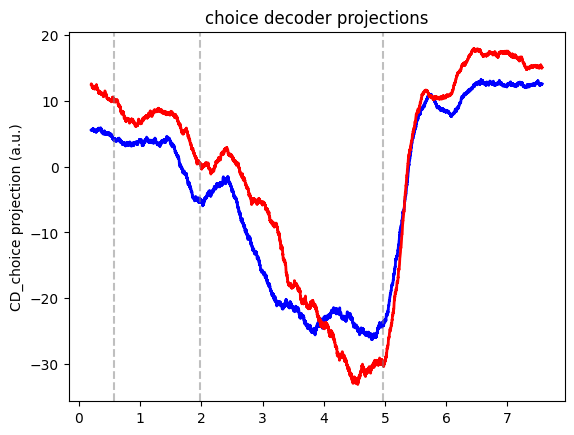

10 trials removed for stability reasons
only ppyr neurons: 295 --> 118
in house train test sorting
time taken: 11.243843793869019
calculation time: 0.08886075019836426


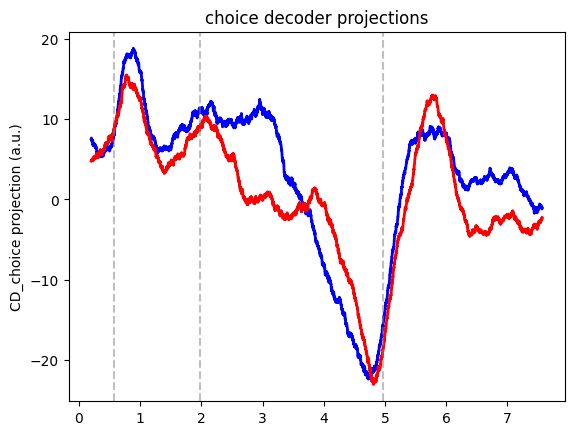

In [14]:
all_norm_right_proj = []
all_norm_left_proj = []
for path in naive_paths:
    s1 = Mode(path, filter_low_perf=False, proportion_train=0.6)#, timestep=1)#, passive=False)
    right_proj, left_proj = s1.plot_CD(mode_input='choice', return_traces=True)

    overall_mean, overall_std = np.mean((right_proj, left_proj)), np.std((right_proj, left_proj))
    right_proj = (right_proj - overall_mean) / overall_std
    left_proj = (left_proj - overall_mean) / overall_std
    all_norm_right_proj.append(right_proj)
    all_norm_left_proj.append(left_proj)



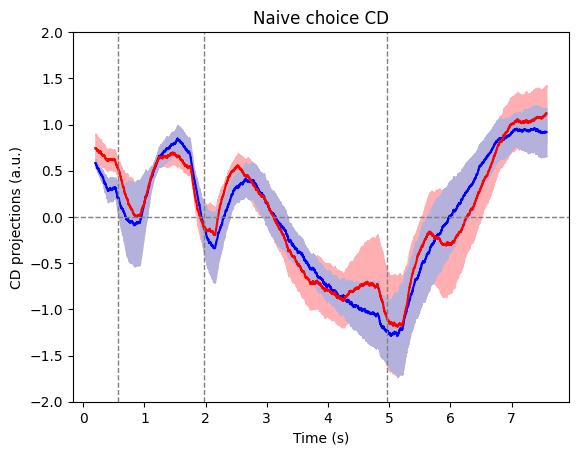

In [15]:
x=s1.t
all_std_right = np.std(all_norm_right_proj, axis=0)[:,0] / np.sqrt(len(all_norm_right_proj))
all_std_left = np.std(all_norm_left_proj, axis=0)[:,0] / np.sqrt(len(all_norm_left_proj))

f=plt.figure()
plt.plot(x,np.mean(all_norm_right_proj, axis=0)[:,0], 'b')
plt.plot(x,np.mean(all_norm_left_proj, axis=0)[:,0], 'r')

plt.fill_between(x, np.mean(all_norm_left_proj, axis=0)[:,0] - all_std_left, 
        np.mean(all_norm_left_proj, axis=0)[:,0] + all_std_left,
        color=['#ffaeb1'])
plt.fill_between(x, np.mean(all_norm_right_proj, axis=0)[:,0] - all_std_right, 
        np.mean(all_norm_right_proj, axis=0)[:,0] + all_std_right,
        color=['#b4b2dc'])


plt.axhline(0, color='gray', linewidth=1, ls='--')
plt.axvline(s1.sample, color='gray', linewidth=1, ls='--')
plt.axvline(s1.delay, color='gray', linewidth=1, ls='--')
plt.axvline(s1.response, color='gray', linewidth=1, ls='--')
plt.xlabel('Time (s)')
plt.ylabel('CD projections (a.u.)')
plt.title('Naive choice CD')
plt.ylim(-2, 2)
plt.savefig(r'P:\paperfigures\fig1\cd_choice_naive.pdf')
plt.show()

### Trained choice CD:

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 175
in house train test sorting
time taken: 15.690178155899048
calculation time: 0.16039323806762695


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


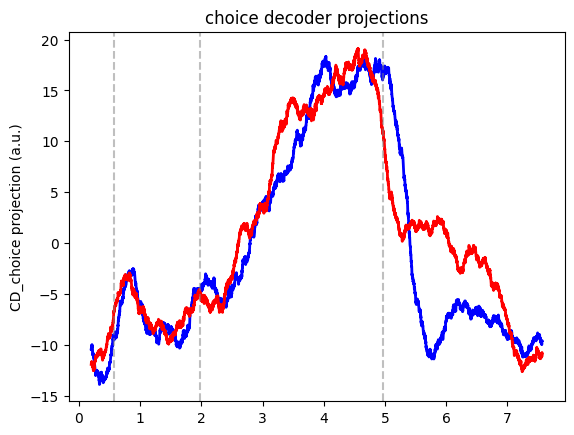

Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 264
in house train test sorting
time taken: 29.449768781661987
calculation time: 0.24603915214538574


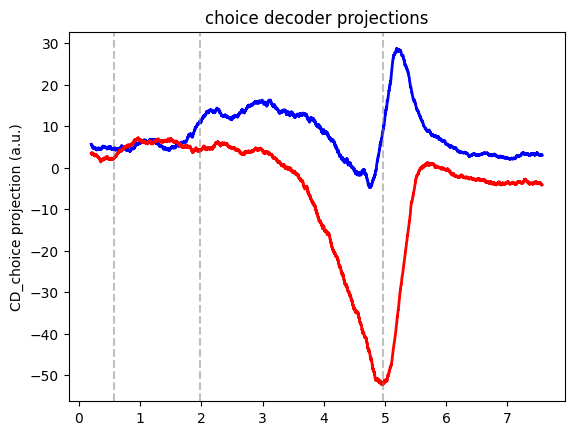

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 361
in house train test sorting
time taken: 60.81219696998596
calculation time: 0.2783679962158203


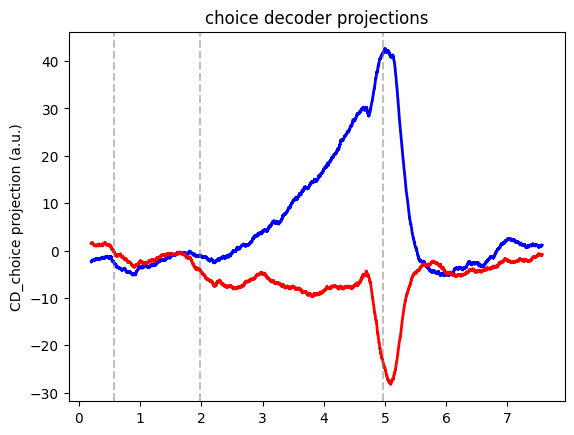

Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 279
in house train test sorting
time taken: 33.64967322349548
calculation time: 0.19908809661865234


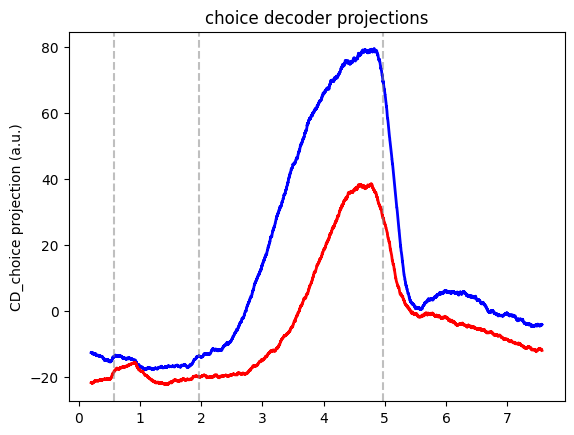

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 151
in house train test sorting
time taken: 14.924068689346313
calculation time: 0.11456084251403809


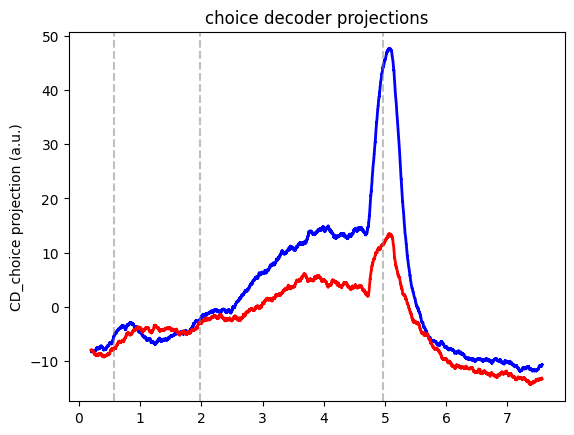

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 344
in house train test sorting
time taken: 37.307190895080566
calculation time: 0.25276899337768555


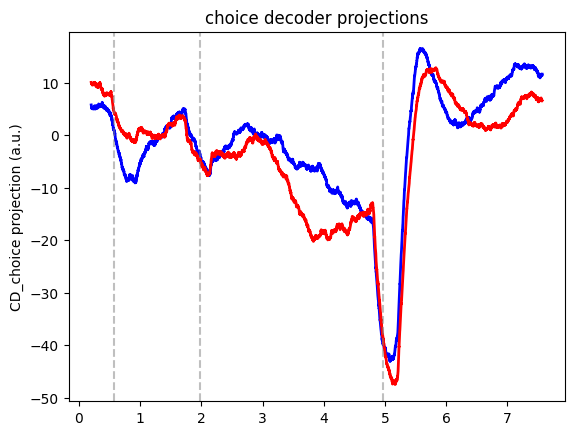

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 238
in house train test sorting
time taken: 28.67702555656433
calculation time: 0.17615771293640137


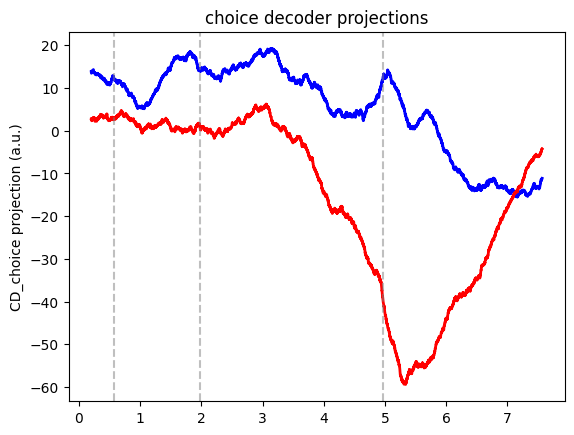

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 287
in house train test sorting
time taken: 32.99050974845886
calculation time: 0.20808887481689453


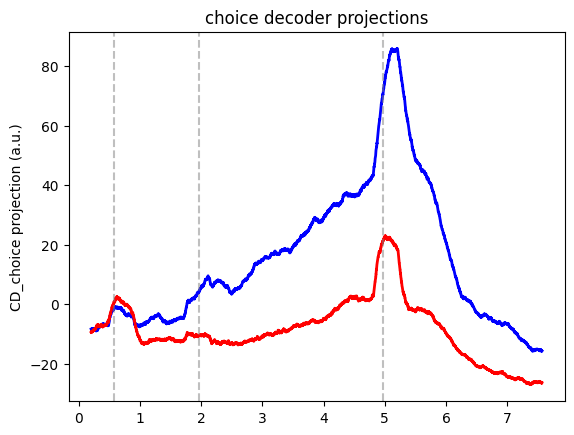

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 287
in house train test sorting
time taken: 24.559871435165405
calculation time: 0.22662591934204102


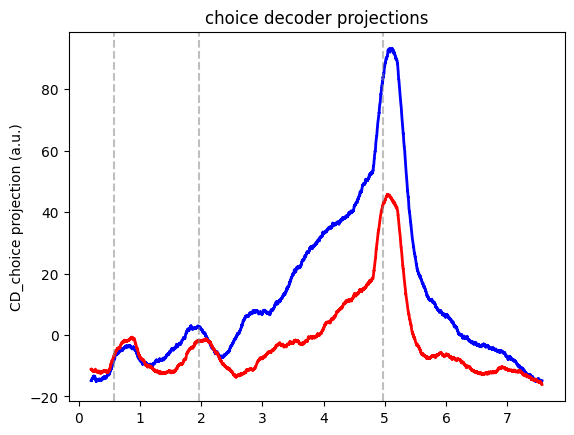

Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 205
in house train test sorting
time taken: 23.745837450027466
calculation time: 0.1525125503540039


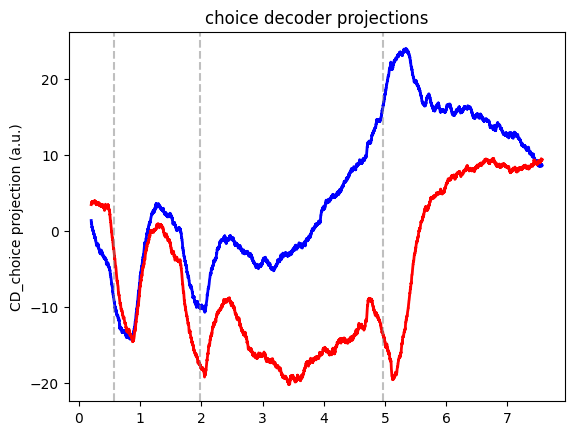

Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 145
in house train test sorting
time taken: 11.62965202331543
calculation time: 0.1365494728088379


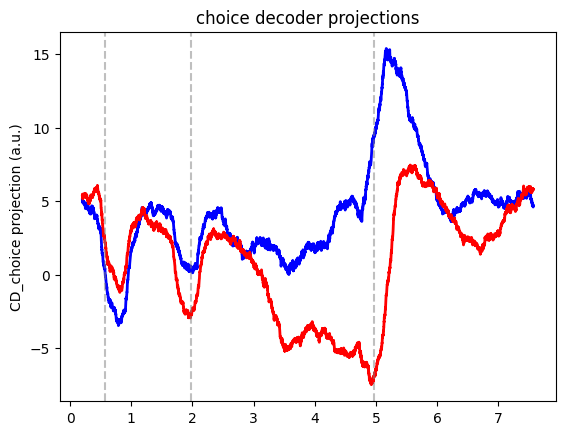

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 343 --> 292
in house train test sorting
time taken: 42.86540365219116
calculation time: 0.23456716537475586


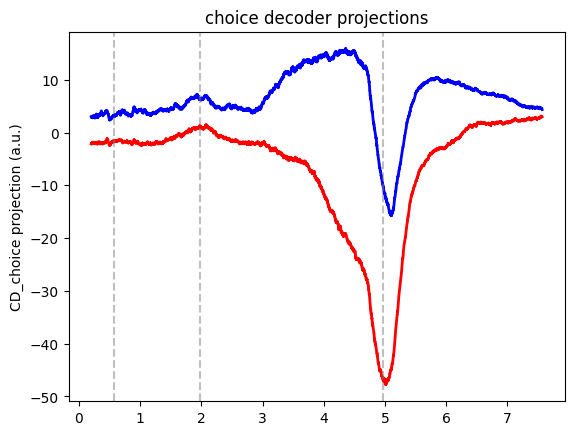

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 516 --> 429
in house train test sorting
time taken: 68.57742810249329
calculation time: 0.3176290988922119


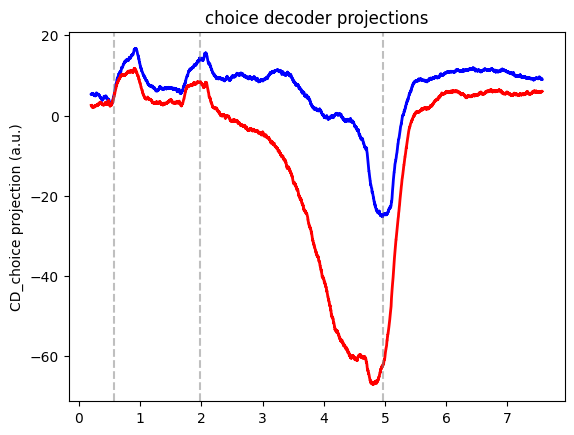

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 361 --> 303
in house train test sorting
time taken: 36.615655183792114
calculation time: 0.22478556632995605


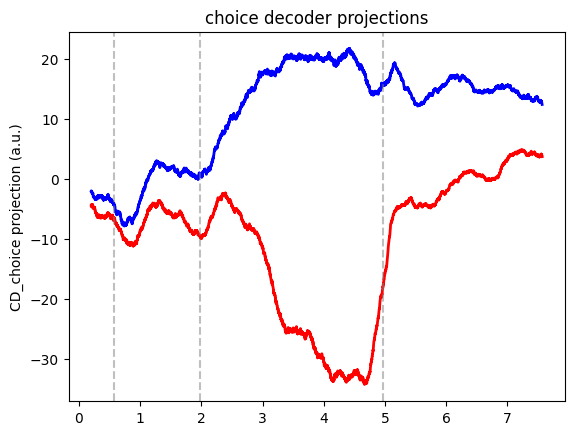

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 192 --> 145
in house train test sorting
time taken: 11.775691270828247
calculation time: 0.11053037643432617


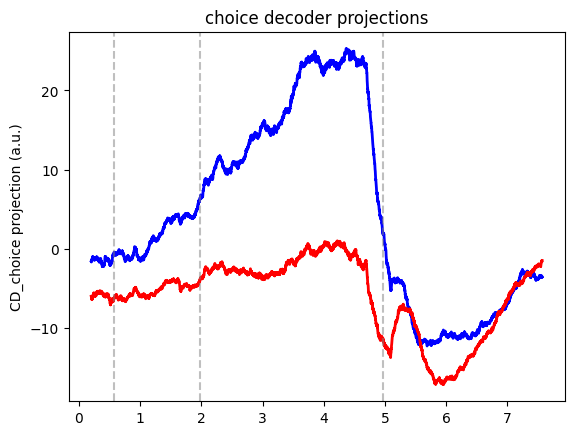

Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 417
in house train test sorting
time taken: 47.87002611160278
calculation time: 0.319561243057251


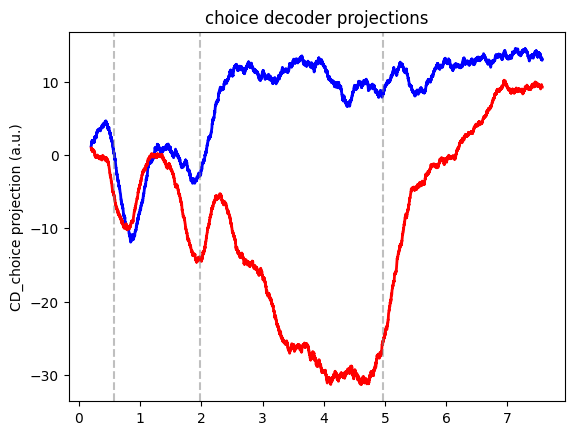

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 368 --> 302
in house train test sorting
time taken: 36.639649391174316
calculation time: 0.2256028652191162


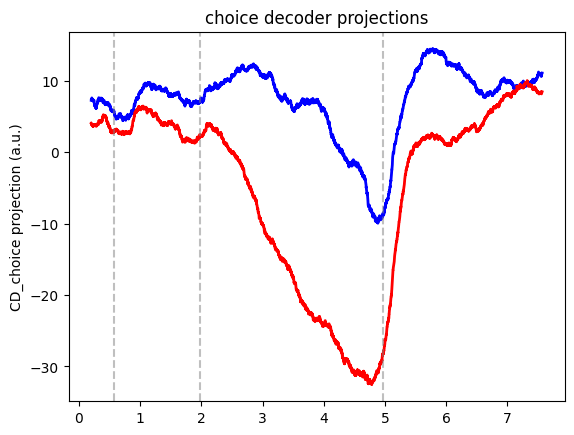

Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 181
in house train test sorting
time taken: 15.520205736160278
calculation time: 0.1395268440246582


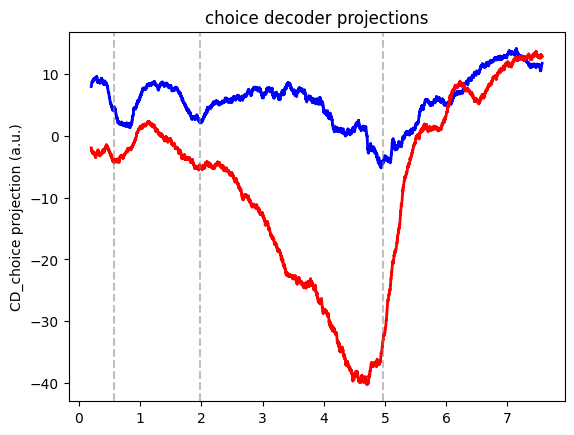

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 203 --> 168
in house train test sorting
time taken: 16.150372982025146
calculation time: 0.13353872299194336


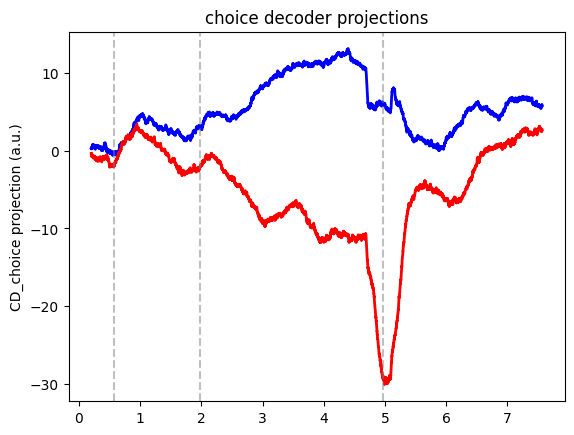

Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 280
in house train test sorting
time taken: 24.86525058746338
calculation time: 0.2547731399536133


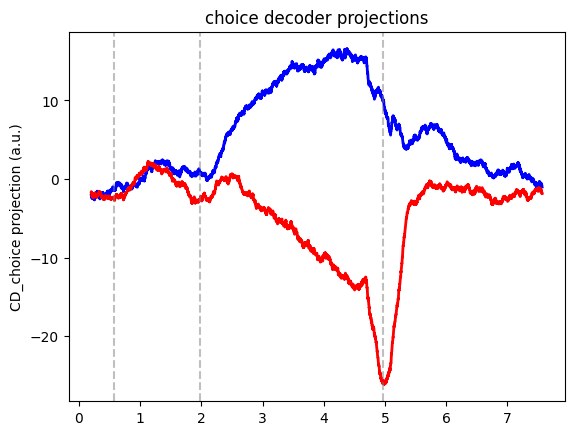

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 167
in house train test sorting
time taken: 11.543606758117676
calculation time: 0.12916970252990723


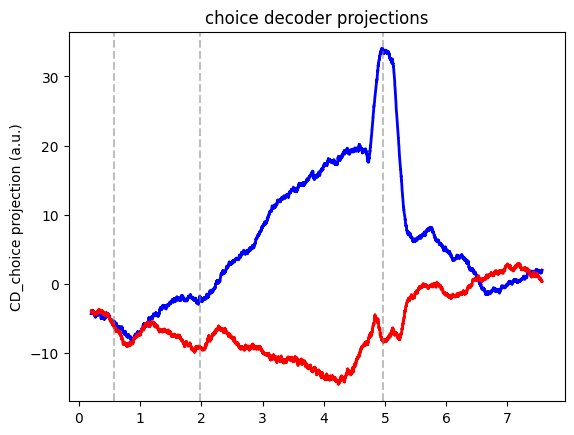

Loading good trial inds from file
31 trials removed for stability reasons
only ppyr neurons: 289 --> 226
in house train test sorting
time taken: 36.1059296131134
calculation time: 0.2012491226196289


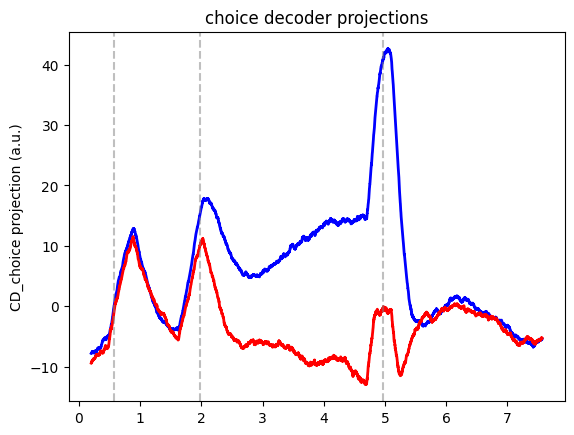

Loading good trial inds from file
52 trials removed for stability reasons
only ppyr neurons: 188 --> 165
in house train test sorting
time taken: 23.22964072227478
calculation time: 0.13555002212524414


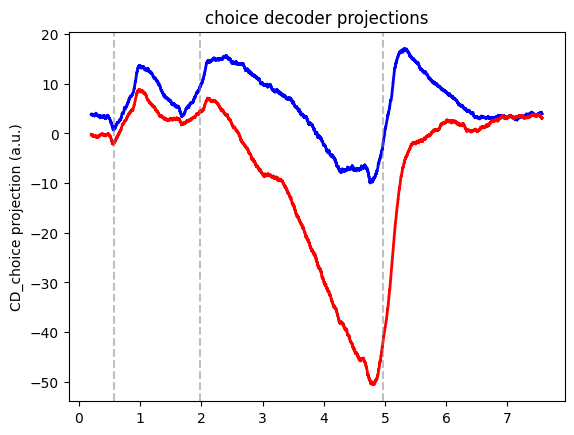

Loading good trial inds from file
18 trials removed for stability reasons
only ppyr neurons: 219 --> 174
in house train test sorting
time taken: 24.72214365005493
calculation time: 0.14062142372131348


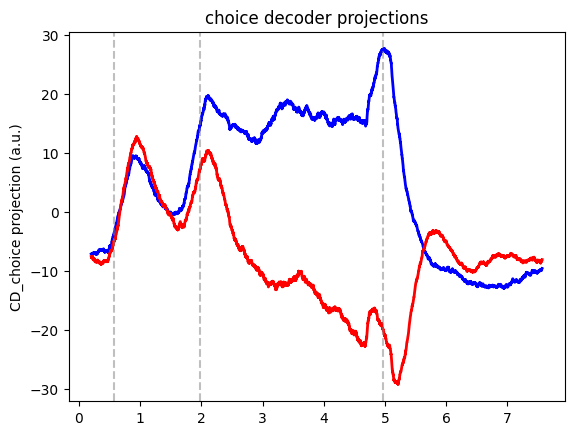

Loading good trial inds from file
26 trials removed for stability reasons
only ppyr neurons: 233 --> 186
in house train test sorting
time taken: 28.620802640914917
calculation time: 0.16252946853637695


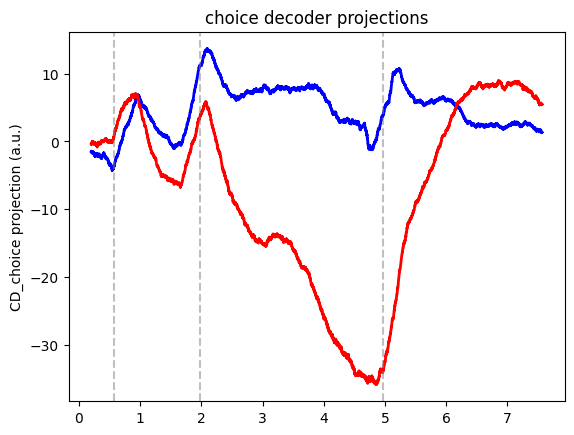

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 172 --> 144
in house train test sorting
time taken: 23.55122995376587
calculation time: 0.12347602844238281


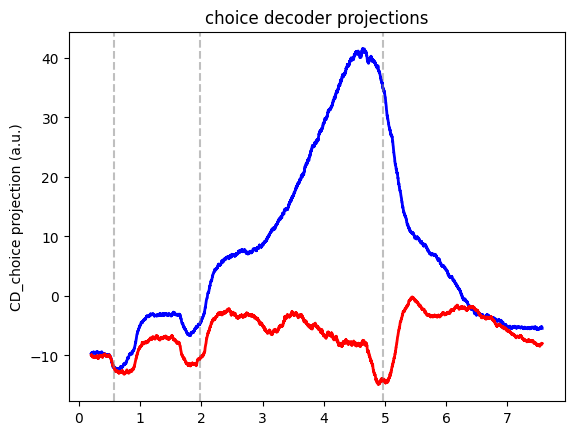

Loading good trial inds from file
16 trials removed for stability reasons
only ppyr neurons: 324 --> 260
in house train test sorting
time taken: 31.611573696136475
calculation time: 0.20612120628356934


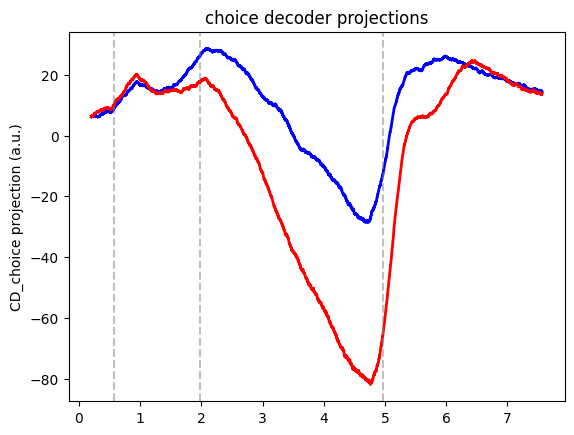

Loading good trial inds from file
61 trials removed for stability reasons
only ppyr neurons: 236 --> 171
in house train test sorting
time taken: 21.187836170196533
calculation time: 0.1491544246673584


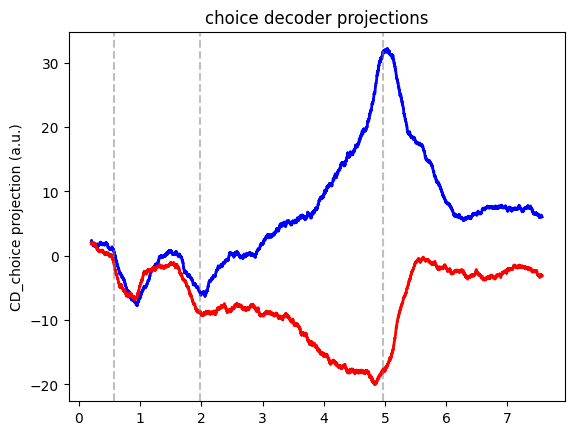

Remove 0 trials from session for bad behavior
15 trials removed for stability reasons
only ppyr neurons: 253 --> 201
in house train test sorting
time taken: 32.587833404541016
calculation time: 0.1699826717376709


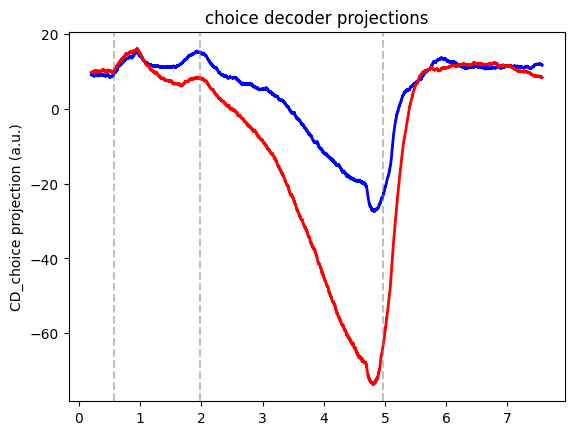

Remove 0 trials from session for bad behavior
6 trials removed for stability reasons
only ppyr neurons: 226 --> 186
in house train test sorting
time taken: 28.4934241771698
calculation time: 0.14437294006347656


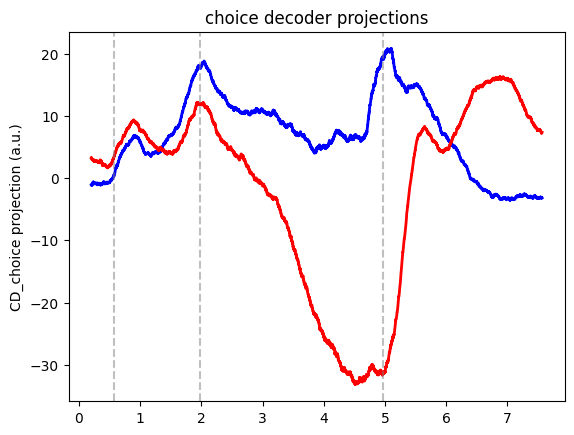

Remove 0 trials from session for bad behavior
30 trials removed for stability reasons
only ppyr neurons: 243 --> 190
in house train test sorting
time taken: 26.679829359054565
calculation time: 0.16308379173278809


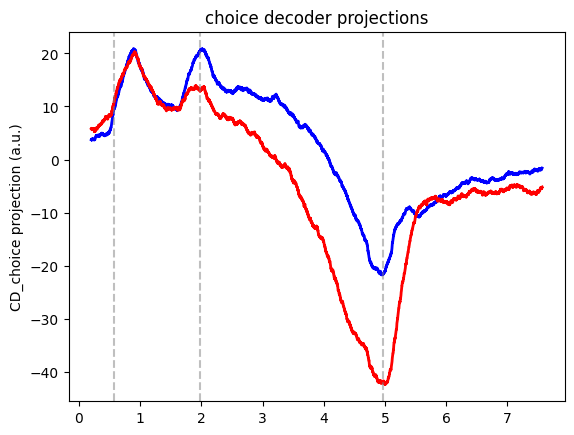

Remove 0 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 308 --> 248
in house train test sorting
time taken: 40.37101602554321
calculation time: 0.1941385269165039


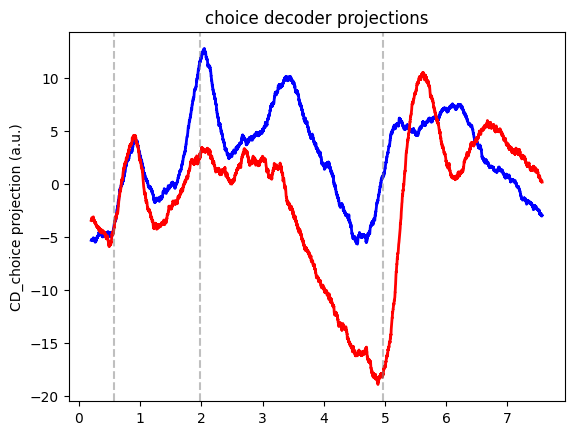

Remove 0 trials from session for bad behavior
14 trials removed for stability reasons
only ppyr neurons: 215 --> 165
in house train test sorting
time taken: 26.880290985107422
calculation time: 0.14252567291259766


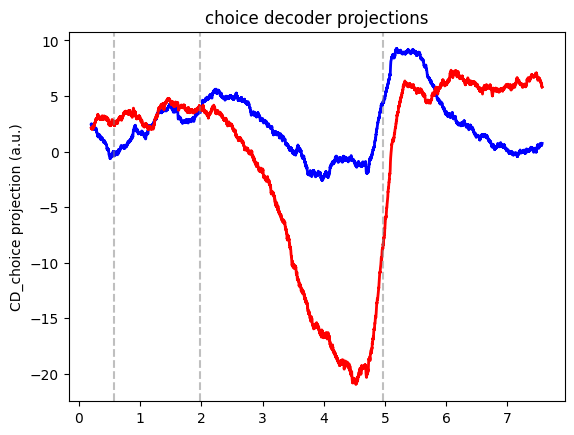

Remove 0 trials from session for bad behavior
2 trials removed for stability reasons
only ppyr neurons: 194 --> 147
in house train test sorting
time taken: 22.22202467918396
calculation time: 0.12525129318237305


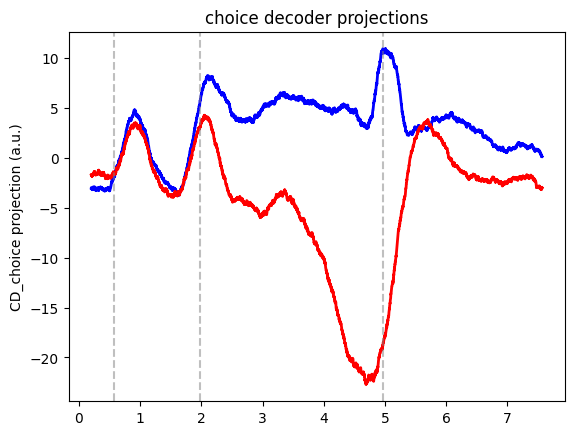

In [17]:
all_norm_right_proj = []
all_norm_left_proj = []
for path in cat(trained_paths):
    s1 = Mode(path, filter_low_perf=True, proportion_train=0.6)#, timestep=1)#, passive=False)
    right_proj, left_proj = s1.plot_CD(mode_input='choice', return_traces=True)

    overall_mean, overall_std = np.mean((right_proj, left_proj)), np.std((right_proj, left_proj))
    right_proj = (right_proj - overall_mean) / overall_std
    left_proj = (left_proj - overall_mean) / overall_std
    all_norm_right_proj.append(right_proj)
    all_norm_left_proj.append(left_proj)



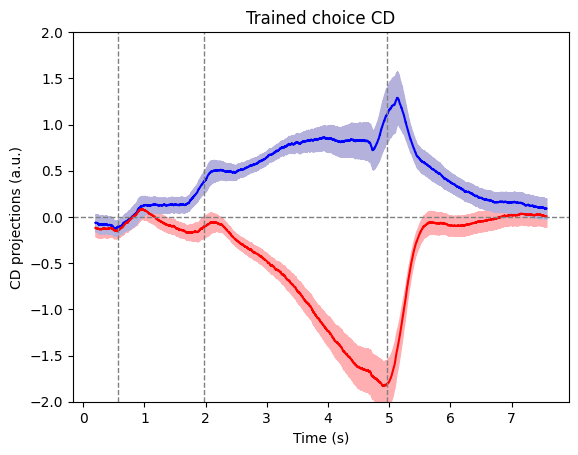

In [18]:
x=s1.t
all_std_right = np.std(all_norm_right_proj, axis=0)[:,0] / np.sqrt(len(all_norm_right_proj))
all_std_left = np.std(all_norm_left_proj, axis=0)[:,0] / np.sqrt(len(all_norm_left_proj))

f=plt.figure()
plt.plot(x,np.mean(all_norm_right_proj, axis=0)[:,0], 'b')
plt.plot(x,np.mean(all_norm_left_proj, axis=0)[:,0], 'r')

plt.fill_between(x, np.mean(all_norm_left_proj, axis=0)[:,0] - all_std_left, 
        np.mean(all_norm_left_proj, axis=0)[:,0] + all_std_left,
        color=['#ffaeb1'])
plt.fill_between(x, np.mean(all_norm_right_proj, axis=0)[:,0] - all_std_right, 
        np.mean(all_norm_right_proj, axis=0)[:,0] + all_std_right,
        color=['#b4b2dc'])


plt.axhline(0, color='gray', linewidth=1, ls='--')
plt.axvline(s1.sample, color='gray', linewidth=1, ls='--')
plt.axvline(s1.delay, color='gray', linewidth=1, ls='--')
plt.axvline(s1.response, color='gray', linewidth=1, ls='--')
plt.xlabel('Time (s)')
plt.ylabel('CD projections (a.u.)')
plt.title('Trained choice CD')
plt.ylim(-2, 2)
plt.savefig(r'P:\paperfigures\fig1\cd_choice_trained.pdf')
plt.show()